# Дифракция второй моды в волноводе с расслоением и жёсткими границами

Численная реализация модового разложения, полученного методом Винера–Хопфа.
Падающая мода: $\cos(\pi y/2b)e^{i\beta z}$. На всех границах выполнено условие Неймана.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [60]:
# =========================
# Параметры задачи
# =========================

f = 179924
c_t = 3.23e3

lmbd = c_t / f
# Малое поглощение k -> k + i0:
k = (2 * np.pi / lmbd) * (1 + 1e-3j)

b = 1.0e-2
c = 2 * b * 0.35          # положение расслоения
d = 2 * b - c

# Падающая вторая мода жёсткого волновода:
#
#     phi_i = cos(pi y / 2b) exp(i beta z),
#
# beta = sqrt(k^2 - (pi / 2b)^2).
#
# Для жёстких границ существует также поршневая мода m = 0,
# однако падает здесь именно первая нетривиальная поперечная мода.

q = np.pi / (2 * b)
beta = np.sqrt(k**2 - q**2)
S = np.sin(q * c)

lmbd_beta = 2 * np.pi / beta
f_beta = c_t / lmbd_beta

print(f'Длина волны падающей моды: {float(np.abs(lmbd_beta)) * 1000:.2f} мм')
print(f'Продольная частота: {float(np.abs(f_beta)) / 1000:.2f} кГц')

Длина волны падающей моды: 20.09 мм
Продольная частота: 160.79 кГц


In [75]:
# =========================
# Сетка и число мод
# =========================

z_min = -20 * lmbd
z_max = 20 * lmbd

M = 50       # число мод в модовых суммах
N = 4000     # число множителей бесконечного произведения K_+

y = np.linspace(0, 2 * b.real, 100, endpoint=True)
z = np.linspace(z_min, z_max, 1000, endpoint=True)

m_full = int(float(np.abs(k.real) * 2 * b / np.pi))
m_lower = int(float(np.abs(k.real) * c / np.pi))
m_upper = int(float(np.abs(k.real) * d / np.pi))

print(
    'Число распространяющихся мод:\n'
    f'  полный волновод: {m_full}\n'
    f'  нижняя ветвь:    {m_lower}\n'
    f'  верхняя ветвь:   {m_upper}'
)

Число распространяющихся мод:
  полный волновод: 2
  нижняя ветвь:    0
  верхняя ветвь:   1


In [76]:
# =========================
# Факторизация K = K_+ K_-
# =========================

def chi(alpha, a, c, d):
    return 1j * (alpha / np.pi) * (
        a * np.log(a) - c * np.log(c) - d * np.log(d)
    )


def K_plus(alpha, a, c, d, N):
    """
    K_+(alpha) из бесконечного произведения Нобла.

    a_n = a/(pi n), c_n = c/(pi n), d_n = d/(pi n).
    """
    res = 1.0 + 0j

    for n in range(1, N + 1):
        a_n = a / (np.pi * n)
        c_n = c / (np.pi * n)
        d_n = d / (np.pi * n)

        res *= (
            (np.sqrt(1 - k**2 * a_n**2 + 0j) - 1j * alpha * a_n)
            /
            (
                (np.sqrt(1 - k**2 * c_n**2 + 0j) - 1j * alpha * c_n)
                *
                (np.sqrt(1 - k**2 * d_n**2 + 0j) - 1j * alpha * d_n)
            )
        )

    res *= np.exp(-chi(alpha, a, c, d))
    return res


def K_minus(alpha):
    """K_-(alpha) = K_+(-alpha)."""
    return K_plus(-alpha, 2 * b, c, d, N)


K_beta = K_plus(beta, 2 * b, c, d, N)
K_k = K_plus(k, 2 * b, c, d, N)

In [77]:
# =========================
# Собственные продольные числа
# =========================

def alpha_full(k, m, b):
    """
    Полный волновод, z < 0:
    sinh(2 gamma b) = 0.

    Для m >= 1:
      alpha_m = +sqrt(k^2 - (pi m / 2b)^2)
    для распространяющихся мод и
      alpha_m = +i sqrt((pi m / 2b)^2 - k^2)
    для эванесцентных мод.

    m=0 отдельно не используется: соответствующая особенность
    в выражении для z<0 является устранимой.
    """
    cutoff = np.pi * m / (2 * b)

    if abs(k.real) >= cutoff:
        return np.sqrt(k**2 - cutoff**2)
    return 1j * np.sqrt(cutoff**2 - k**2)


def alpha_branch(k, m, width):
    """
    Правая ветвь ширины width, z > 0:
    sinh(gamma * width) = 0.

    Контур замыкается в нижней полуплоскости, поэтому
    распространяющаяся мода имеет alpha < 0:
        alpha = -sqrt(k^2 - (pi m / width)^2).

    Для эванесцентной моды:
        alpha = -i sqrt((pi m / width)^2 - k^2).

    m=0 здесь также рассматривается отдельно как полюс alpha=-k.
    """
    cutoff = np.pi * m / width

    if abs(k.real) >= cutoff:
        return -np.sqrt(k**2 - cutoff**2)
    return -1j * np.sqrt(cutoff**2 - k**2)


alpha_full_modes = np.array(
    [alpha_full(k, m, 2 * b) for m in range(1, M + 1)]
)

alpha_lower = np.array(
    [alpha_branch(k, m, c) for m in range(1, M + 1)]
)

alpha_upper = np.array(
    [alpha_branch(k, m, d) for m in range(1, M + 1)]
)

K_full_modes = np.array(
    [K_plus(alpha_m, 2 * b, c, d, N) for alpha_m in alpha_full_modes]
)

K_lower = np.array(
    [K_minus(alpha_m) for alpha_m in alpha_lower]
)

K_upper = np.array(
    [K_minus(alpha_m) for alpha_m in alpha_upper]
)

In [78]:
# =========================
# Поля
# =========================

def phi_i(y, z):
    """Падающая вторая мода жёсткого волновода."""
    return np.cos(q * y) * np.exp(1j * beta * z)


def phi_left(y, z):
    """
    Поле для z < 0.

    Здесь полное поле:
        phi_t = phi_i + phi_left.

    Получается суперпозиция собственных мод полного волновода.
    Вклад m=0 является устранимой особенностью и в этот ряд не входит.
    """
    res = 0j

    for j, m in enumerate(range(1, M + 1)):
        alpha_m = alpha_full_modes[j]
        gamma_m = np.pi * m / (2j * b)

        res += (
            K_full_modes[j]
            * np.sin(q * c * m)
            * gamma_m
            /
            (
                (alpha_m + k)
                * (alpha_m + beta)
                * alpha_m
            )
            * np.cos(np.pi * m * y / (2 * b))
            * np.exp(-1j * alpha_m * z)
        )

    # Исправленный вариант формулы (39):
    # обязательно присутствует exp(-i alpha_m z).
    res *= (
        1j * np.pi * K_beta * S
        /
        (2 * b * (beta + k) * c * d)
    )

    return res


def phi_right_lower(y, z):
    """
    Полное поле в правой нижней ветви:
        z > 0, 0 <= y <= c.

    Полюс alpha=-beta сокращает падающую моду phi_i.
    Поэтому итоговое полное поле непосредственно задаётся
    собственными модами канала ширины c.

    Отдельно учитывается поршневая мода m=0, возникшая из полюса alpha=-k.
    """
    # Поршневая мода
    res = (
        S / (c * q)
        * K_beta / K_k
        * np.exp(1j * k * z)
    )

    # Моды m >= 1
    for j, m in enumerate(range(1, M + 1)):
        alpha_m = alpha_lower[j]

        coeff = (
            -q * S * K_beta
            / (c * (beta + k))
            * (-1) ** m
            * (alpha_m - k)
            /
            (
                alpha_m
                * (alpha_m + beta)
                * K_lower[j]
            )
        )

        res += (
            coeff
            * np.cos(np.pi * m * y / c)
            * np.exp(-1j * alpha_m * z)
        )

    return res


def phi_right_upper(y, z):
    """
    Полное поле в правой верхней ветви:
        z > 0, c <= y <= 2b.

    Полюс alpha=-k даёт поршневую моду верхнего канала.
    Остальные полюса alpha_n определяются шириной d = 2b-c.
    """
    # Поршневая мода
    res = (
        -S / (d * q)
        * K_beta / K_k
        * np.exp(1j * k * z)
    )

    # Моды m >= 1
    for j, m in enumerate(range(1, M + 1)):
        alpha_m = alpha_upper[j]

        coeff = (
            q * S * K_beta
            / (d * (beta + k))
            * (-1) ** m
            * (alpha_m - k)
            /
            (
                alpha_m
                * (alpha_m + beta)
                * K_upper[j]
            )
        )

        res += (
            coeff
            * np.cos(np.pi * m * (2 * b - y) / d)
            * np.exp(-1j * alpha_m * z)
        )

    return res

In [79]:
# =========================
# Сетка полного поля
# =========================

phi = np.zeros((len(y), len(z)), dtype=complex)
phi_t = np.zeros((len(y), len(z)), dtype=complex)

z_0_index = int(len(z) / 2)
y_c_index = int(np.where(y >= c.real)[0][0])

# z < 0
for i in range(len(y)):
    for j in range(z_0_index):
        phi[i, j] = phi_left(y[i], z[j])
        phi_t[i, j] = phi_i(y[i], z[j]) + phi[i, j]

# z > 0, нижняя ветвь
for i in range(y_c_index):
    for j in range(z_0_index, len(z)):
        phi_t[i, j] = phi_right_lower(y[i], z[j])
        phi[i, j] = phi_t[i, j] - phi_i(y[i], z[j])

# z > 0, верхняя ветвь
for i in range(y_c_index, len(y)):
    for j in range(z_0_index, len(z)):
        phi_t[i, j] = phi_right_upper(y[i], z[j])
        phi[i, j] = phi_t[i, j] - phi_i(y[i], z[j])

In [80]:
# =========================
# Простые проверки граничных условий
# =========================

zt = z[int(0.7 * len(z))]
zn = z[int(0.3 * len(z))]

print('\nПроверка значений полного поля:')
print('phi_t(y=0, z>0):      ', phi_right_lower(0.0, zt))
print('phi_t(y=c-, z>0):    ', phi_right_lower(c, zt))
print('phi_t(y=c+, z>0):    ', phi_right_upper(c, zt))
print('phi_t(y=2b, z>0):    ', phi_right_upper(2 * b, zt))
print('phi_t(y=0, z<0):     ', phi_i(0.0, zn) + phi_left(0.0, zn))
print('phi_t(y=2b, z<0):    ', phi_i(2 * b, zn) + phi_left(2 * b, zn))


Проверка значений полного поля:
phi_t(y=0, z>0):       (0.740792458258589+0.11060722480004616j)
phi_t(y=c-, z>0):     (0.740792458258589+0.11060722480004616j)
phi_t(y=c+, z>0):     (-0.14074842551683808-0.6449332212247498j)
phi_t(y=2b, z>0):     (-0.6570280679924112+0.5258177483631616j)
phi_t(y=0, z<0):      (0.5762266634515514-0.986323356728564j)
phi_t(y=2b, z<0):     (-0.7842428239331766+0.6118377222162948j)


In [81]:
# =========================
# Визуализация
# =========================

width = 15
height = int(width * 2 * b / (abs(z_min) + abs(z_max)))
if height < 3:
    height = 3

Z, Y = np.meshgrid(z, y)

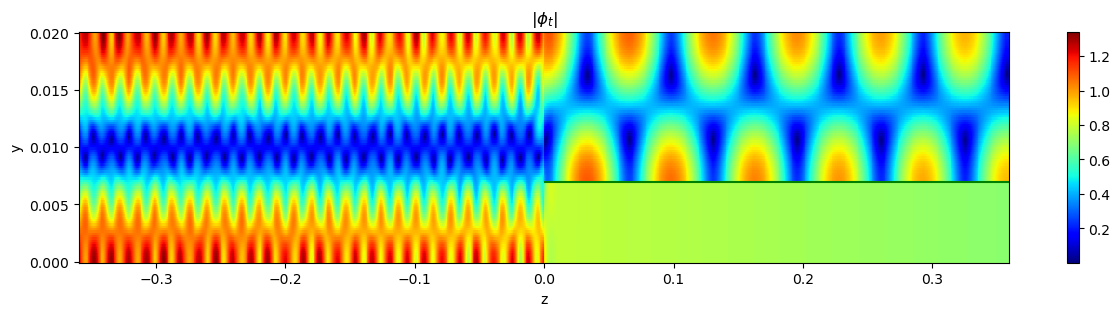

In [82]:
plt.figure(figsize=(width, height))
plt.pcolormesh(Z, Y, np.abs(phi_t), cmap='jet', shading='auto')
plt.hlines(c.real, 0, z_max, color='green')
plt.colorbar()
plt.xlabel('z')
plt.ylabel('y')
plt.title(r'$|\phi_t|$')
plt.show()

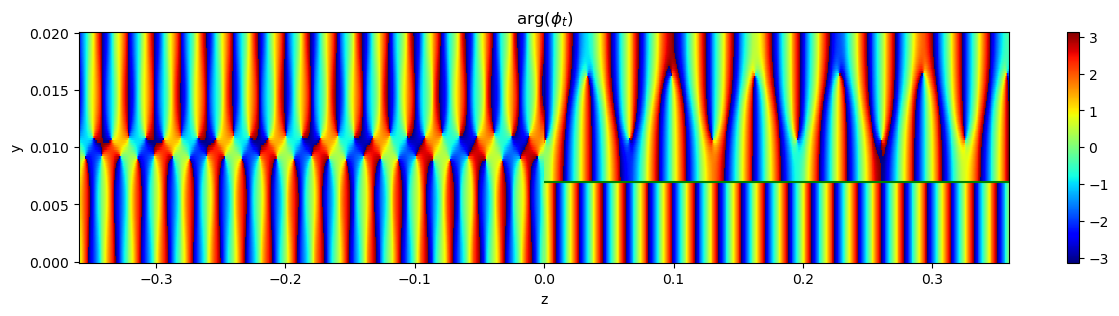

In [83]:
plt.figure(figsize=(width, height))
plt.pcolormesh(Z, Y, np.angle(phi_t), cmap='jet', shading='auto')
plt.hlines(c.real, 0, z_max, color='green')
plt.colorbar()
plt.xlabel('z')
plt.ylabel('y')
plt.title(r'$\arg(\phi_t)$')
plt.show()

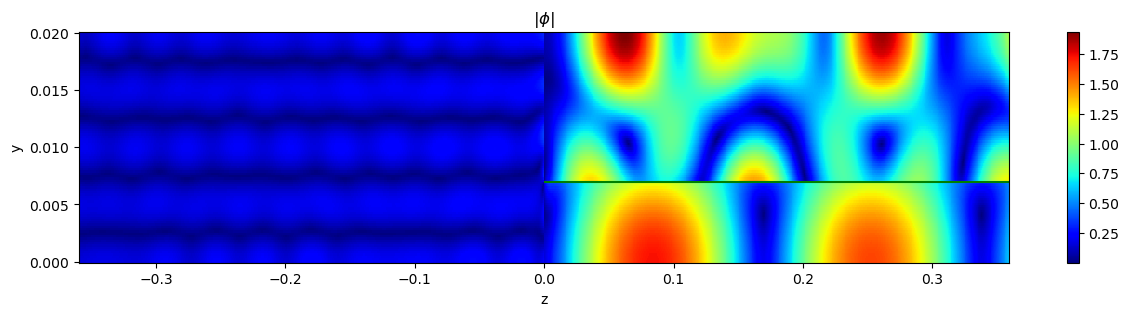

In [84]:
plt.figure(figsize=(width, height))
plt.pcolormesh(Z, Y, np.abs(phi), cmap='jet', shading='auto')
plt.hlines(c.real, 0, z_max, color='green')
plt.colorbar()
plt.xlabel('z')
plt.ylabel('y')
plt.title(r'$|\phi|$')
plt.show()

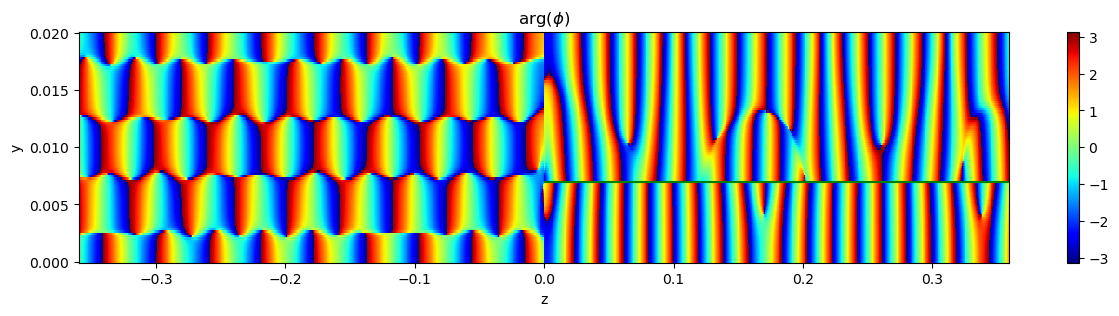

In [85]:
plt.figure(figsize=(width, height))
plt.pcolormesh(Z, Y, np.angle(phi), cmap='jet', shading='auto')
plt.hlines(c.real, 0, z_max, color='green')
plt.colorbar()
plt.xlabel('z')
plt.ylabel('y')
plt.title(r'$\arg(\phi)$')
plt.show()

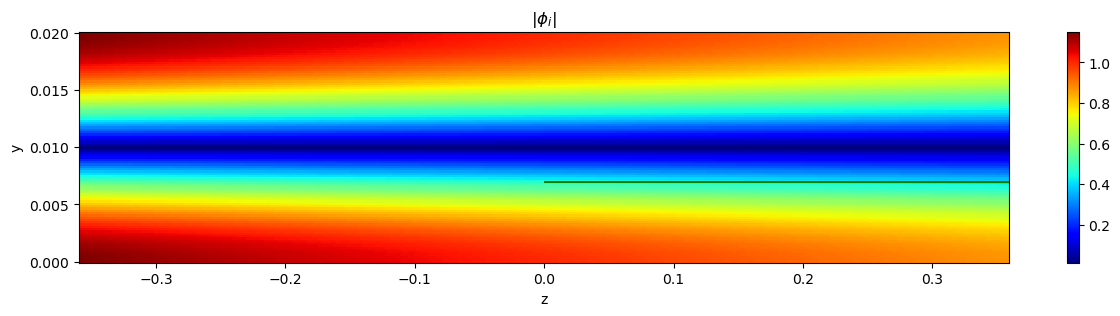

In [86]:
phi_incident = np.zeros((len(y), len(z)), dtype=complex)
for i in range(len(y)):
    for j in range(len(z)):
        phi_incident[i, j] = phi_i(y[i], z[j])

plt.figure(figsize=(width, height))
plt.pcolormesh(Z, Y, np.abs(phi_incident), cmap='jet', shading='auto')
plt.hlines(c.real, 0, z_max, color='green')
plt.colorbar()
plt.xlabel('z')
plt.ylabel('y')
plt.title(r'$|\phi_i|$')
plt.show()

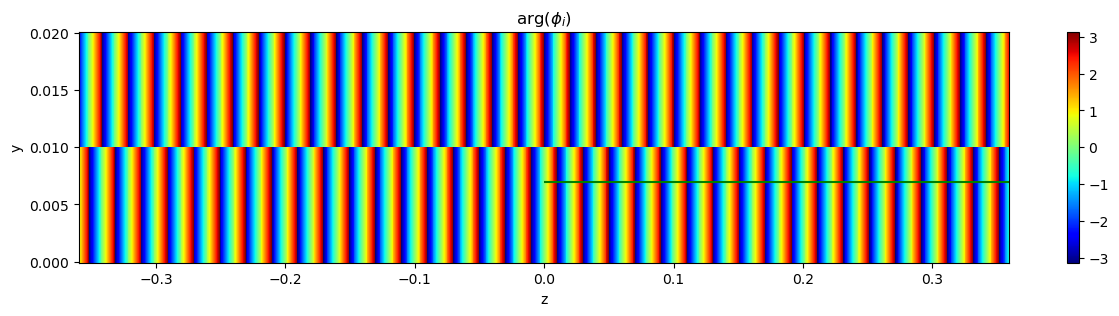

In [87]:
plt.figure(figsize=(width, height))
plt.pcolormesh(Z, Y, np.angle(phi_incident), cmap='jet', shading='auto')
plt.hlines(c.real, 0, z_max, color='green')
plt.colorbar()
plt.xlabel('z')
plt.ylabel('y')
plt.title(r'$\arg(\phi_i)$')
plt.show()

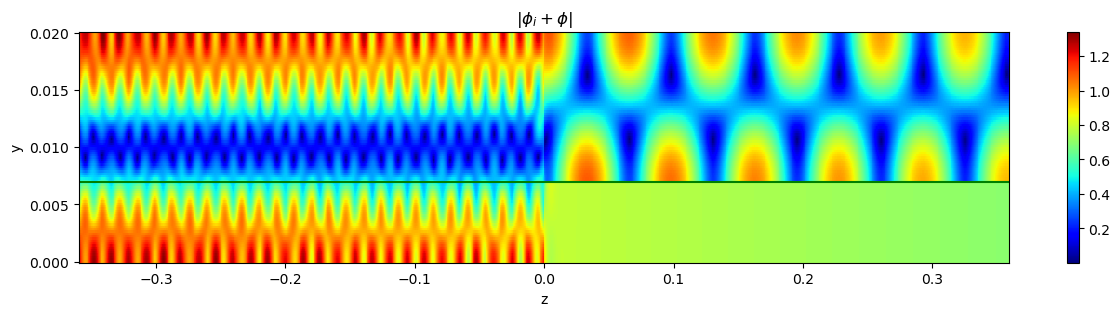

In [88]:
plt.figure(figsize=(width, height))
plt.pcolormesh(Z, Y, np.abs(phi_incident + phi), cmap='jet', shading='auto')
plt.hlines(c.real, z_min, z_max, color='green')
plt.colorbar()
plt.xlabel('z')
plt.ylabel('y')
plt.title(r'$|\phi_i+\phi|$')
plt.show()